In [ ]:
# the purpose of this notebook is to perform spearman/ pearson, partial dependence, permutation analysis on GPR model

In [1]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

print()

In [2]:
# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
raw_data_summary = df[formula_cols + measured_target_cols].copy()
raw_data_summary[formula_cols] = raw_data_summary[formula_cols].fillna(0.0)
raw_data_summary[measured_target_cols] = raw_data_summary[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(raw_data_summary) == 25, (
    f"Expected the 25 original samples; found {len(raw_data_summary)}."
)
display(raw_data_summary)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


,Ingredient,Property,n,Pearson r,Pearson p,Spearman rho,Spearman p
0,TEM,Avg_Density_g_cm3,25,-0.8742,0.0000,-0.6934,0.0001
1,TEM,24h_avg_pct absorption,25,0.6310,0.0007,0.6934,0.0001
2,TEM,24h_avg_pct_retention,25,-0.3497,0.0866,-0.3883,0.0551
3,Joncryl,Avg_Density_g_cm3,25,-0.3748,0.0649,-0.5210,0.0076
4,Joncryl,24h_avg_pct absorption,25,-0.0098,0.9630,0.1021,0.6271
5,Joncryl,24h_avg_pct_retention,25,0.0457,0.8284,-0.0400,0.8493
6,NC513,Avg_Density_g_cm3,25,-0.0223,0.9156,-0.0327,0.8767
7,NC513,24h_avg_pct absorption,25,0.1485,0.4786,-0.0402,0.8489
8,NC513,24h_avg_pct_retention,25,0.2891,0.1610,0.3558,0.0809
9,PEG-DE,Avg_Density_g_cm3,25,-0.4150,0.0391,-0.4652,0.0191


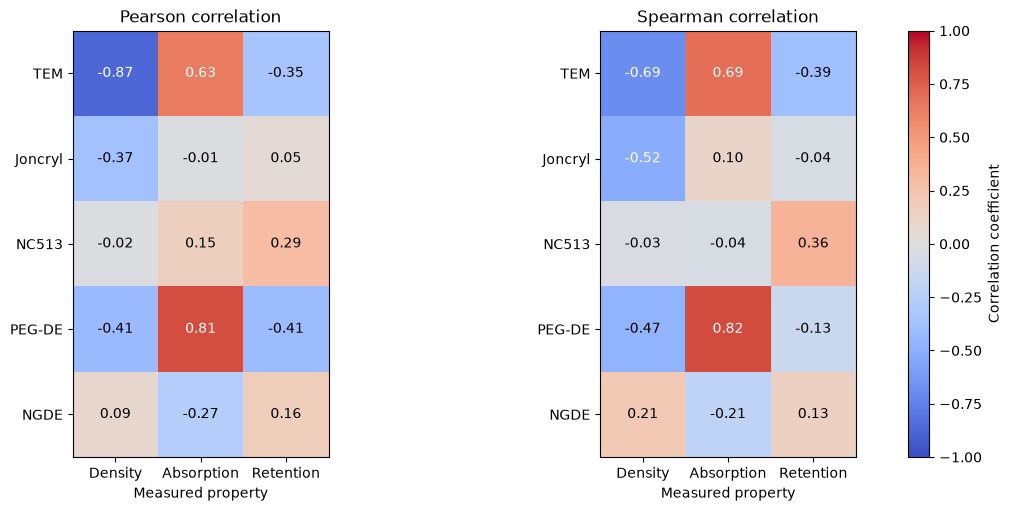

In [3]:
# pearson and spearman

import pandas as pd
from scipy.stats import pearsonr, spearmanr

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]

rows = []

for ingredient in feature_cols:
    for target in target_cols:
        pair = df[[ingredient, target]].copy()

        # Blank chain-extender amounts mean that ingredient was not used.
        if ingredient != "TEM":
            pair[ingredient] = pair[ingredient].fillna(0)

        pair = pair.apply(pd.to_numeric, errors="coerce").dropna()

        r, pearson_p = pearsonr(pair[ingredient], pair[target])
        rho, spearman_p = spearmanr(pair[ingredient], pair[target])

        rows.append({
            "Ingredient": ingredient,
            "Property": target,
            "n": len(pair),
            "Pearson r": r,
            "Pearson p": pearson_p,
            "Spearman rho": rho,
            "Spearman p": spearman_p,
        })

correlations = pd.DataFrame(rows)
display(correlations.round(4))

import matplotlib.pyplot as plt
import numpy as np

target_labels = {
    "Avg_Density_g_cm3": "Density",
    "24h_avg_pct absorption": "Absorption",
    "24h_avg_pct_retention": "Retention",
}

heatmap_specs = [
    ("Pearson r", "Pearson correlation"),
    ("Spearman rho", "Spearman correlation"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, (value_col, title) in zip(axes, heatmap_specs):
    matrix = (
        correlations
        .pivot(index="Ingredient", columns="Property", values=value_col)
        .reindex(index=feature_cols, columns=target_cols)
    )

    image = ax.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)

    ax.set_xticks(
        range(len(target_cols)),
        labels=[target_labels[target] for target in target_cols],
    )
    ax.set_yticks(range(len(feature_cols)), labels=feature_cols)
    ax.set_title(title)
    ax.set_xlabel("Measured property")

    for row in range(len(feature_cols)):
        for col in range(len(target_cols)):
            value = matrix.iloc[row, col]
            ax.text(
                col,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if abs(value) >= 0.5 else "black",
            )

fig.colorbar(image, ax=axes, label="Correlation coefficient")
plt.show()


In [4]:
# load the gpr_models

import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")

c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages

Mean CV RMSE by property:


,Mean CV RMSE
Property,
24h_avg_pct absorption,26.8661
24h_avg_pct_retention,10.5825
Avg_Density_g_cm3,0.0255


Permutation importance: mean increase in held-out MSE


Property,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
Ingredient,,,
TEM,0.00398,1001.49816,14.49422
Joncryl,0.00070,198.74489,102.79897
NC513,0.00050,-13.53410,52.05902
PEG-DE,0.00002,6091.08259,80.35629
NGDE,0.00006,249.37492,8.30998


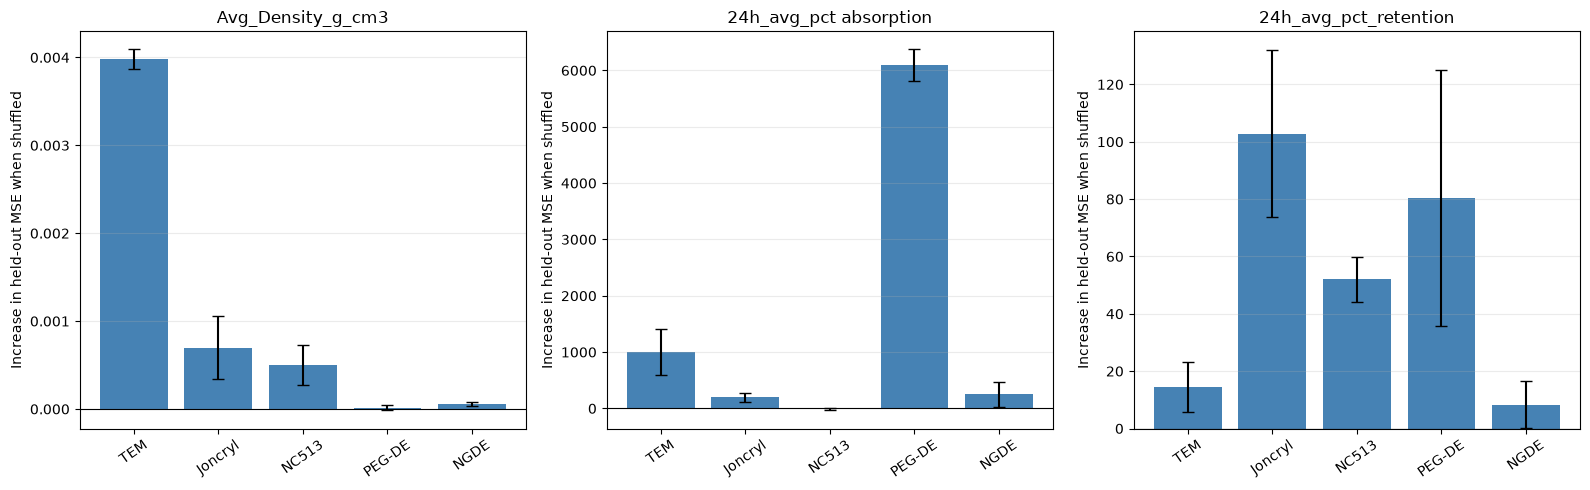

In [5]:
# permutation analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_squared_error

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]

n_splits = 5
n_repeats = 3
n_permutations = 10
rng = np.random.default_rng(2026)

importance_rows = []
baseline_rows = []

for target in target_cols:
    target_data = df[feature_cols + [target]].copy()
    target_data[feature_cols] = target_data[feature_cols].fillna(0.0)
    target_data[target] = pd.to_numeric(target_data[target], errors="coerce")
    target_data = target_data.dropna(subset=[target])

    X_target = target_data[feature_cols]
    y_target = target_data[target].to_numpy()

    cv = RepeatedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=42,
    )
    split_iterator = iter(cv.split(X_target, y_target))

    for repeat in range(n_repeats):
        baseline_sse = 0.0
        permuted_sse = {
            feature: np.zeros(n_permutations)
            for feature in feature_cols
        }
        n_test = 0

        for _ in range(n_splits):
            train_idx, test_idx = next(split_iterator)
            X_train = X_target.iloc[train_idx]
            X_test = X_target.iloc[test_idx]
            y_train = y_target[train_idx]
            y_test = y_target[test_idx]

            # Clone the trained model's pipeline, then fit it only on this fold.
            fold_model = clone(gpr_models[target]).fit(X_train, y_train)

            baseline_pred = fold_model.predict(X_test)
            baseline_sse += np.sum((y_test - baseline_pred) ** 2)
            n_test += len(y_test)

            for feature in feature_cols:
                for permutation in range(n_permutations):
                    X_permuted = X_test.copy()
                    X_permuted[feature] = rng.permutation(
                        X_permuted[feature].to_numpy()
                    )
                    permuted_pred = fold_model.predict(X_permuted)
                    permuted_sse[feature][permutation] += np.sum(
                        (y_test - permuted_pred) ** 2
                    )

        baseline_mse = baseline_sse / n_test
        baseline_rows.append({
            "Property": target,
            "Repeat": repeat + 1,
            "CV RMSE": np.sqrt(baseline_mse),
        })

        for feature in feature_cols:
            delta_mse = permuted_sse[feature] / n_test - baseline_mse
            importance_rows.append({
                "Property": target,
                "Ingredient": feature,
                "Repeat": repeat + 1,
                "Importance": delta_mse.mean(),
            })

importance = pd.DataFrame(importance_rows)
importance_summary = (
    importance.groupby(["Property", "Ingredient"])["Importance"]
    .agg(["mean", "std"])
    .reset_index()
)

print("Mean CV RMSE by property:")
display(
    pd.DataFrame(baseline_rows)
    .groupby("Property")["CV RMSE"]
    .mean()
    .rename("Mean CV RMSE")
    .to_frame()
    .round(4)
)

print("Permutation importance: mean increase in held-out MSE")
display(
    importance_summary.pivot(
        index="Ingredient",
        columns="Property",
        values="mean",
    )
    .reindex(index=feature_cols, columns=target_cols)
    .round(5)
)

# Plot each target separately because their MSE scales differ.
fig, axes = plt.subplots(1, len(target_cols), figsize=(16, 5))

for ax, target in zip(axes, target_cols):
    target_summary = (
        importance_summary[importance_summary["Property"] == target]
        .set_index("Ingredient")
        .reindex(feature_cols)
    )

    ax.bar(
        feature_cols,
        target_summary["mean"],
        yerr=target_summary["std"],
        capsize=4,
        color="steelblue",
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(target)
    ax.set_ylabel("Increase in held-out MSE when shuffled")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

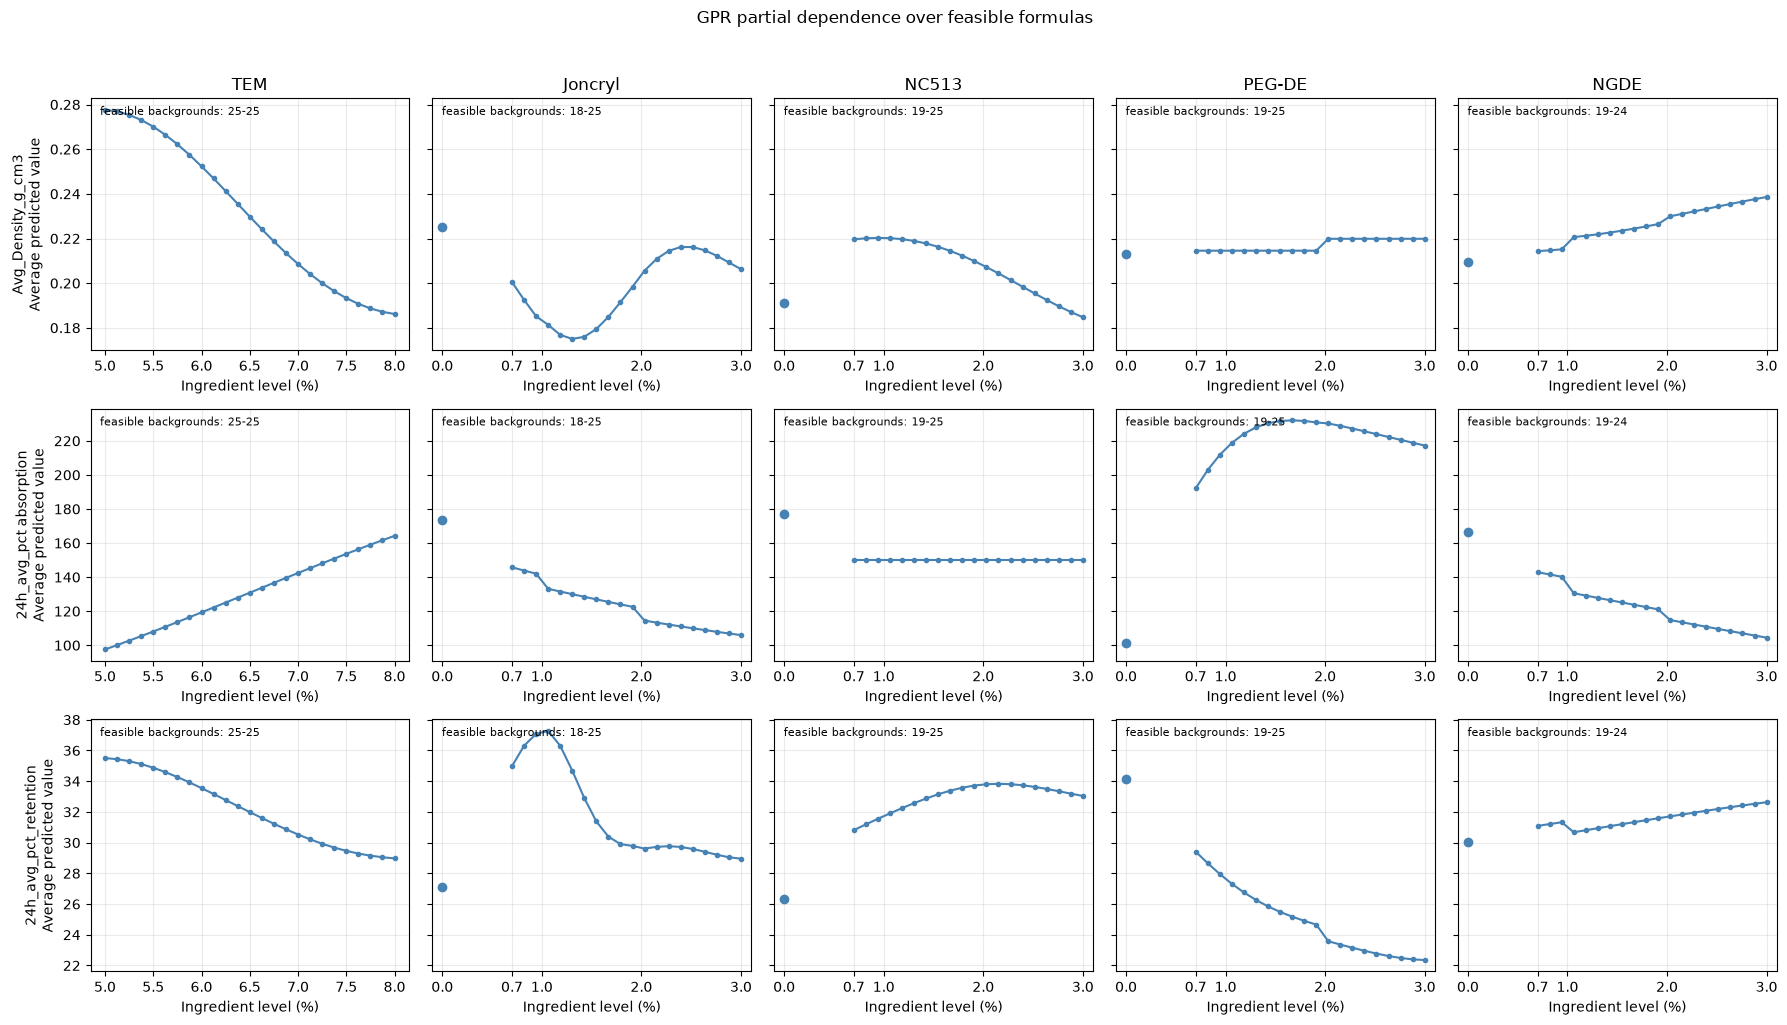

,Property,Ingredient,Minimum feasible backgrounds,Maximum feasible backgrounds
0,Avg_Density_g_cm3,TEM,25,25
1,Avg_Density_g_cm3,Joncryl,18,25
2,Avg_Density_g_cm3,NC513,19,25
3,Avg_Density_g_cm3,PEG-DE,19,25
4,Avg_Density_g_cm3,NGDE,19,24
5,24h_avg_pct absorption,TEM,25,25
6,24h_avg_pct absorption,Joncryl,18,25
7,24h_avg_pct absorption,NC513,19,25
8,24h_avg_pct absorption,PEG-DE,19,25
9,24h_avg_pct absorption,NGDE,19,24


In [7]:
# Feasible-background partial dependence for each ingredient and GPR target.
# Chain-extender curves use only formulas that remain within the candidate constraints.
import numpy as np
import matplotlib.pyplot as plt

chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_grids = {
    "TEM": np.linspace(5.0, 8.0, 25),
    **{
        ingredient: np.linspace(0.7, 3.0, 20)
        for ingredient in chain_extender_cols
    },
}

fig, axes = plt.subplots(
    len(target_cols),
    len(feature_cols),
    figsize=(18, 10),
    sharey="row",
)
feasible_counts = {}

for row, target in enumerate(target_cols):
    target_data = raw_data_summary.dropna(subset=[target])
    background = target_data[feature_cols].copy()
    background = background.loc[background["TEM"].between(5.0, 8.0)]
    model = gpr_models[target]

    for col, feature in enumerate(feature_cols):
        ax = axes[row, col]
        grid = feature_grids[feature]
        pd_means = []
        counts = []
        evaluation_values = (
            np.concatenate(([0.0], grid))
            if feature in chain_extender_cols
            else grid
        )

        for value in evaluation_values:
            X_eval = background.copy()
            X_eval[feature] = value

            if feature in chain_extender_cols:
                extender_values = X_eval[chain_extender_cols]
                levels_valid = (
                    extender_values.eq(0.0)
                    | (extender_values.ge(0.7) & extender_values.le(3.0))
                ).all(axis=1)
                total_valid = extender_values.sum(axis=1).between(0.7, 6.0)
                valid = levels_valid & total_valid
            else:
                valid = X_eval["TEM"].between(5.0, 8.0)

            X_eval = X_eval.loc[valid, feature_cols]
            counts.append(len(X_eval))
            if X_eval.empty:
                pd_means.append(np.nan)
            else:
                pd_means.append(model.predict(X_eval).mean())

        feasible_counts[(target, feature)] = counts
        if feature in chain_extender_cols:
            ax.plot(grid, pd_means[1:], color="steelblue", marker="o", markersize=3)
            ax.scatter([0.0], [pd_means[0]], color="steelblue", zorder=3)
            ax.set_xlim(-0.1, 3.1)
            ax.set_xticks([0.0, 0.7, 1.0, 2.0, 3.0])
        else:
            ax.plot(grid, pd_means, color="steelblue", marker="o", markersize=3)

        ax.grid(alpha=0.25)
        ax.set_title(feature if row == 0 else "")
        ax.set_xlabel("Ingredient level (%)")
        if col == 0:
            ax.set_ylabel(f"{target}\nAverage predicted value")
        ax.text(
            0.03,
            0.97,
            f"feasible backgrounds: {min(counts)}-{max(counts)}",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
        )

fig.suptitle("GPR partial dependence over feasible formulas", y=1.02)
fig.tight_layout()
plt.show()

display(
    pd.DataFrame(
        [
            {
                "Property": target,
                "Ingredient": feature,
                "Minimum feasible backgrounds": min(feasible_counts[(target, feature)]),
                "Maximum feasible backgrounds": max(feasible_counts[(target, feature)]),
            }
            for target in target_cols
            for feature in feature_cols
        ]
    )
)

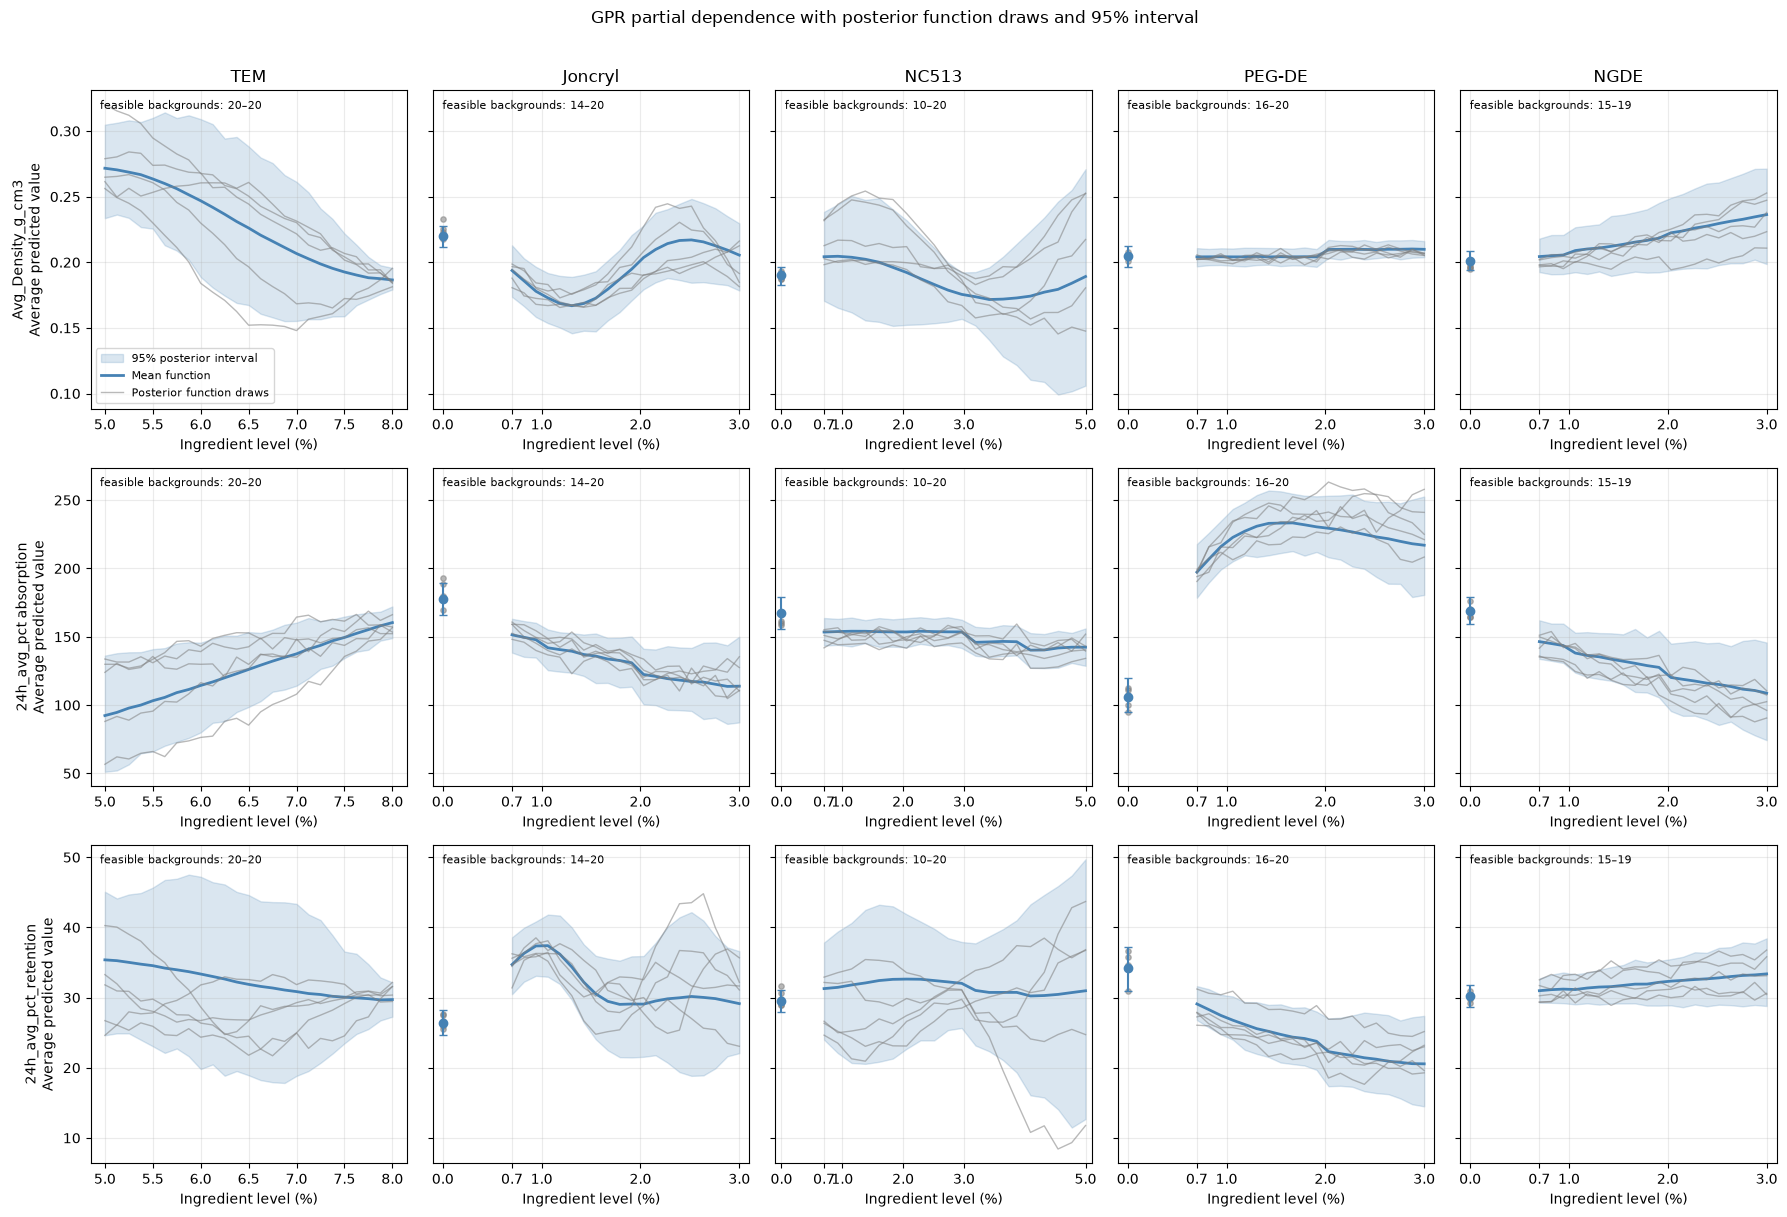

In [10]:
# partial dependence analysis with better visuals 
import numpy as np
import matplotlib.pyplot as plt

chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
lower_by_col = {col: 0.7 for col in chain_extender_cols}
upper_by_col = {
    "Joncryl": 3.0,
    "NC513": 5.0,  # NC513's allowable upper limit
    "PEG-DE": 3.0,
    "NGDE": 3.0,
}

feature_grids = {
    "TEM": np.linspace(5.0, 8.0, 25),
    **{
        ingredient: np.linspace(
            lower_by_col[ingredient], upper_by_col[ingredient], 20
        )
        for ingredient in chain_extender_cols
    },
}

background_sample_size = 20
n_posterior_samples = 200
n_function_draws_to_plot = 5
rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    len(target_cols),
    len(feature_cols),
    figsize=(18, 4 * len(target_cols)),
    sharey="row",
    squeeze=False,
)

def sample_pipeline_posterior(pipeline, X, n_samples, random_state):
    # Apply the pipeline's input transformations.
    X_transformed = X
    for _, step in pipeline.steps[:-1]:
        if step is None or (isinstance(step, str) and step == "passthrough"):
            continue
        X_transformed = step.transform(X_transformed)

    # Draw samples from the final Gaussian Process estimator.
    gp = pipeline.steps[-1][1]
    if not hasattr(gp, "sample_y"):
        raise TypeError(
            f"The pipeline's final step ({type(gp).__name__}) "
            "does not provide sample_y()."
        )

    return gp.sample_y(
        X_transformed,
        n_samples=n_samples,
        random_state=random_state,
    )

for row, target in enumerate(target_cols):
    target_data = raw_data_summary.dropna(subset=[target, *feature_cols])
    background = target_data[feature_cols].copy()
    background = background.loc[background["TEM"].between(5.0, 8.0)]

    if len(background) > background_sample_size:
        background = background.sample(
            n=background_sample_size,
            random_state=42,
        )

    model = gpr_models[target]

    for col, feature in enumerate(feature_cols):
        ax = axes[row, col]
        grid = feature_grids[feature]
        evaluation_values = (
            np.concatenate(([0.0], grid))
            if feature in chain_extender_cols
            else grid
        )

        # Build feasible background formulas for each value on the x-axis.
        eval_groups = []
        feasible_counts = []

        for value in evaluation_values:
            X_eval = background.copy()
            X_eval[feature] = value

            if feature in chain_extender_cols:
                extender_values = X_eval[chain_extender_cols]
                levels_valid = np.ones(len(X_eval), dtype=bool)

                for ingredient in chain_extender_cols:
                    levels_valid &= (
                        extender_values[ingredient].eq(0.0)
                        | extender_values[ingredient].between(
                            lower_by_col[ingredient],
                            upper_by_col[ingredient],
                        )
                    )

                total_valid = extender_values.sum(axis=1).between(0.7, 6.0)
                valid = levels_valid & total_valid
            else:
                valid = X_eval["TEM"].between(5.0, 8.0)

            X_eval = X_eval.loc[valid, feature_cols]
            eval_groups.append(X_eval)
            feasible_counts.append(len(X_eval))

        nonempty_groups = [group for group in eval_groups if not group.empty]

        if not nonempty_groups:
            ax.set_title(feature if row == 0 else "")
            ax.text(0.5, 0.5, "No feasible formulas", ha="center", va="center",
                    transform=ax.transAxes)
            continue

        # Draw joint posterior functions across the feasible background formulas.
        X_joint = pd.concat(nonempty_groups, ignore_index=True)
        posterior_draws = sample_pipeline_posterior(
            model,
            X_joint,
            n_samples=n_posterior_samples,
            random_state=42 + row * len(feature_cols) + col,
        )

        # Average predictions over the feasible backgrounds at each x value.
        curve_draws = np.full(
            (len(evaluation_values), n_posterior_samples),
            np.nan,
        )
        offset = 0

        for i, group in enumerate(eval_groups):
            n_rows = len(group)
            if n_rows:
                curve_draws[i] = posterior_draws[
                    offset : offset + n_rows
                ].mean(axis=0)
                offset += n_rows

        curve_mean = np.nanmean(curve_draws, axis=1)
        lower = np.nanpercentile(curve_draws, 2.5, axis=1)
        upper = np.nanpercentile(curve_draws, 97.5, axis=1)

        draw_indices = rng.choice(
            n_posterior_samples,
            size=min(n_function_draws_to_plot, n_posterior_samples),
            replace=False,
        )

        if feature in chain_extender_cols:
            # Keep zero (inactive ingredient) separate from positive amounts.
            ax.fill_between(
                grid,
                lower[1:],
                upper[1:],
                color="steelblue",
                alpha=0.2,
                label="95% posterior interval",
            )
            ax.plot(
                grid,
                curve_mean[1:],
                color="steelblue",
                linewidth=2,
                label="Mean function",
            )
            ax.errorbar(
                [0.0],
                [curve_mean[0]],
                yerr=[[curve_mean[0] - lower[0]], [upper[0] - curve_mean[0]]],
                fmt="o",
                color="steelblue",
                capsize=3,
            )

            for draw_idx in draw_indices:
                ax.plot(
                    grid,
                    curve_draws[1:, draw_idx],
                    color="gray",
                    alpha=0.55,
                    linewidth=1,
                    label="Posterior function draws" if draw_idx == draw_indices[0] else None,
                )
                ax.scatter(
                    [0.0],
                    [curve_draws[0, draw_idx]],
                    color="gray",
                    alpha=0.55,
                    s=15,
                )

            ax.set_xlim(-0.1, upper_by_col[feature] + 0.1)
            ax.set_xticks(
                sorted(set([0.0, 0.7, 1.0, 2.0, 3.0, upper_by_col[feature]]))
            )
        else:
            ax.fill_between(
                grid,
                lower,
                upper,
                color="steelblue",
                alpha=0.2,
                label="95% posterior interval",
            )
            ax.plot(
                grid,
                curve_mean,
                color="steelblue",
                linewidth=2,
                label="Mean function",
            )

            for draw_idx in draw_indices:
                ax.plot(
                    grid,
                    curve_draws[:, draw_idx],
                    color="gray",
                    alpha=0.55,
                    linewidth=1,
                    label="Posterior function draws" if draw_idx == draw_indices[0] else None,
                )

        ax.grid(alpha=0.25)
        ax.set_title(feature if row == 0 else "")
        ax.set_xlabel("Ingredient level (%)")

        if col == 0:
            ax.set_ylabel(f"{target}\nAverage predicted value")

        ax.text(
            0.03,
            0.97,
            f"feasible backgrounds: {min(feasible_counts)}–{max(feasible_counts)}",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
        )

fig.suptitle(
    "GPR partial dependence with posterior function draws and 95% interval",
    y=1.01,
)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
